In [1]:
#PAH ligands by pose: Where do my poses bind?
#General tools
import numpy as np
import pandas as pd
import seaborn as sns
import os
import pymol2


#Coded tools, you need to connect it manually sometimes
#CHANGE FUNCTION DEPENDING ON GOAL
from src.generate_graph_new import protein_pocket, make_protein_ligand_complex

#Heatmap tools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap


In [2]:
#Create your pocket docking data
#Remember that it is important: Where is my storage dir? Where is my result dir? How many folders do I have?

#Define your directories
dock_pdbqt_dir = '/data/projects/Chemdocking/dock_score/stabilizer_with_poses/'
protein_pdb_dir = "/data/projects/Chemdocking/VirtualDockingLab/data/screen_8000/protein/target.pdb"
complex_pdb_dir = "tmp/complex.pdb"
complex_csv_dir = "complex.csv"
pocket_res = '/projectbig/jupyternotebook/jrivera/output/pocket_results/new'



In [3]:
#Docking filtering and selection though ligand pose

#This code is slightly different from 02. because now we take a look at all of the poses
#This time it is different than the other times because of several reasons: 
#1. The input files are more processed, they have now a pdb file and not a pdqbt file
#2. The input files were already separed by poses, therefore it does not need the multiple poses that we get in the 02.

#Main differences: We define pose number and for no_stabilizer_weak we need to make a code that selects 100 random folders. 
#random_files = random.sample(file, 100)

#Define pose 
pos_num = '2'


#Define iteration through folders and subfolders
for folder in os.listdir(dock_pdbqt_dir):
    sub_folder= os.path.join(dock_pdbqt_dir, folder)
    
    #Define your desired pose and access the folder
    if folder.split('_') [1] == pos_num:
        
        for file in os.listdir(sub_folder):
            file_path = os.path.join(sub_folder, file)

            if file.split('.') [1] != 'pdb':
                continue
            print(file)
        
            #Make temporary folder                                           
            if not os.path.exists("tmp"):
                os.mkdir("tmp")
                
            #Create protein pocket with 6 arms as threshold
            ! /home/jrivera/envs/chem/bin/obabel {file_path} -O tmp/ligand_pose_number.sdf
           
            make_protein_ligand_complex(protein_pdb_dir, "tmp/ligand_pose_number.sdf", complex_pdb_dir)
            #The file path needs to make different poses
            
            pocket = protein_pocket(complex_pdb_dir, ligand_id = 'UNK', threshold = 6)

            #Give your file the correct name and path to save
            
           
                    
            csv_file_name = file.split('.')[0] + '.csv'
                    
            docking_dir = os.path.join(pocket_res, csv_file_name)
                    
            print(docking_dir)
                        
            if not os.path.exists(docking_dir):
                pocket.to_csv(docking_dir)
    
            os.system("rm -r tmp") 

dock_smina_PAH_6N1K_9_pose_2_stabilizer.pdb
1 molecule converted
/projectbig/jupyternotebook/jrivera/output/pocket_results/new/dock_smina_PAH_6N1K_9_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_0_pose_2_stabilizer.pdb
1 molecule converted
/projectbig/jupyternotebook/jrivera/output/pocket_results/new/dock_smina_PAH_6N1K_0_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_56_pose_2_stabilizer.pdb
1 molecule converted
/projectbig/jupyternotebook/jrivera/output/pocket_results/new/dock_smina_PAH_6N1K_56_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_62_pose_2_stabilizer.pdb
1 molecule converted
/projectbig/jupyternotebook/jrivera/output/pocket_results/new/dock_smina_PAH_6N1K_62_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_55_pose_2_stabilizer.pdb
1 molecule converted
/projectbig/jupyternotebook/jrivera/output/pocket_results/new/dock_smina_PAH_6N1K_55_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_38_pose_2_stabilizer.pdb
1 molecule converted
/projectbig/jupyternotebook/jrivera/output/pocket_results/new/dock_smina_

In [5]:
#Ligand preparation for heatmap
#Filtering through poses

PAH_ligands= {}


#Define iteration through folders and subfolders
#for folder in os.listdir(pocket_res):
#sub_folder= os.path.join(pocket_res, folder)  
    
for file in os.listdir(pocket_res):
    file_path = os.path.join(pocket_res, file)
    if file.split('.') [1] != 'csv':
        continue

    #Define the pose you want to extract   
    if file.split('_') [6] == '2':
        print(file)    #Checkpoint: what files am i opening?
                
            
    ligands = pd.read_csv(file_path)

    ligands_processed = []

    for i in range(453):
        if i in list(ligands['index']):
            ligands_processed.append(1)
        else:
            ligands_processed.append(0)


    PAH_ligands[file.split('_')[4]] = ligands_processed
            
    #PAH_ligands.to_csv('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/stabilizers/stabilizers_pose_2')
            
    #print (PAH_ligands)

dock_smina_PAH_6N1K_9_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_0_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_56_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_62_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_55_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_38_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_8_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_37_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_10_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_39_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_61_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_40_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_59_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_6_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_15_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_58_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_12_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_1_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_14_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_35_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_34_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_5_pose_2_stabilizer.csv
dock_smina_PAH_6

In [6]:
#Dictionary processing

PAH_ligands_sorted = dict(sorted(PAH_ligands.items(), key=lambda item: int(item[0])))

df_PAH_ligands = pd.DataFrame(PAH_ligands_sorted).T

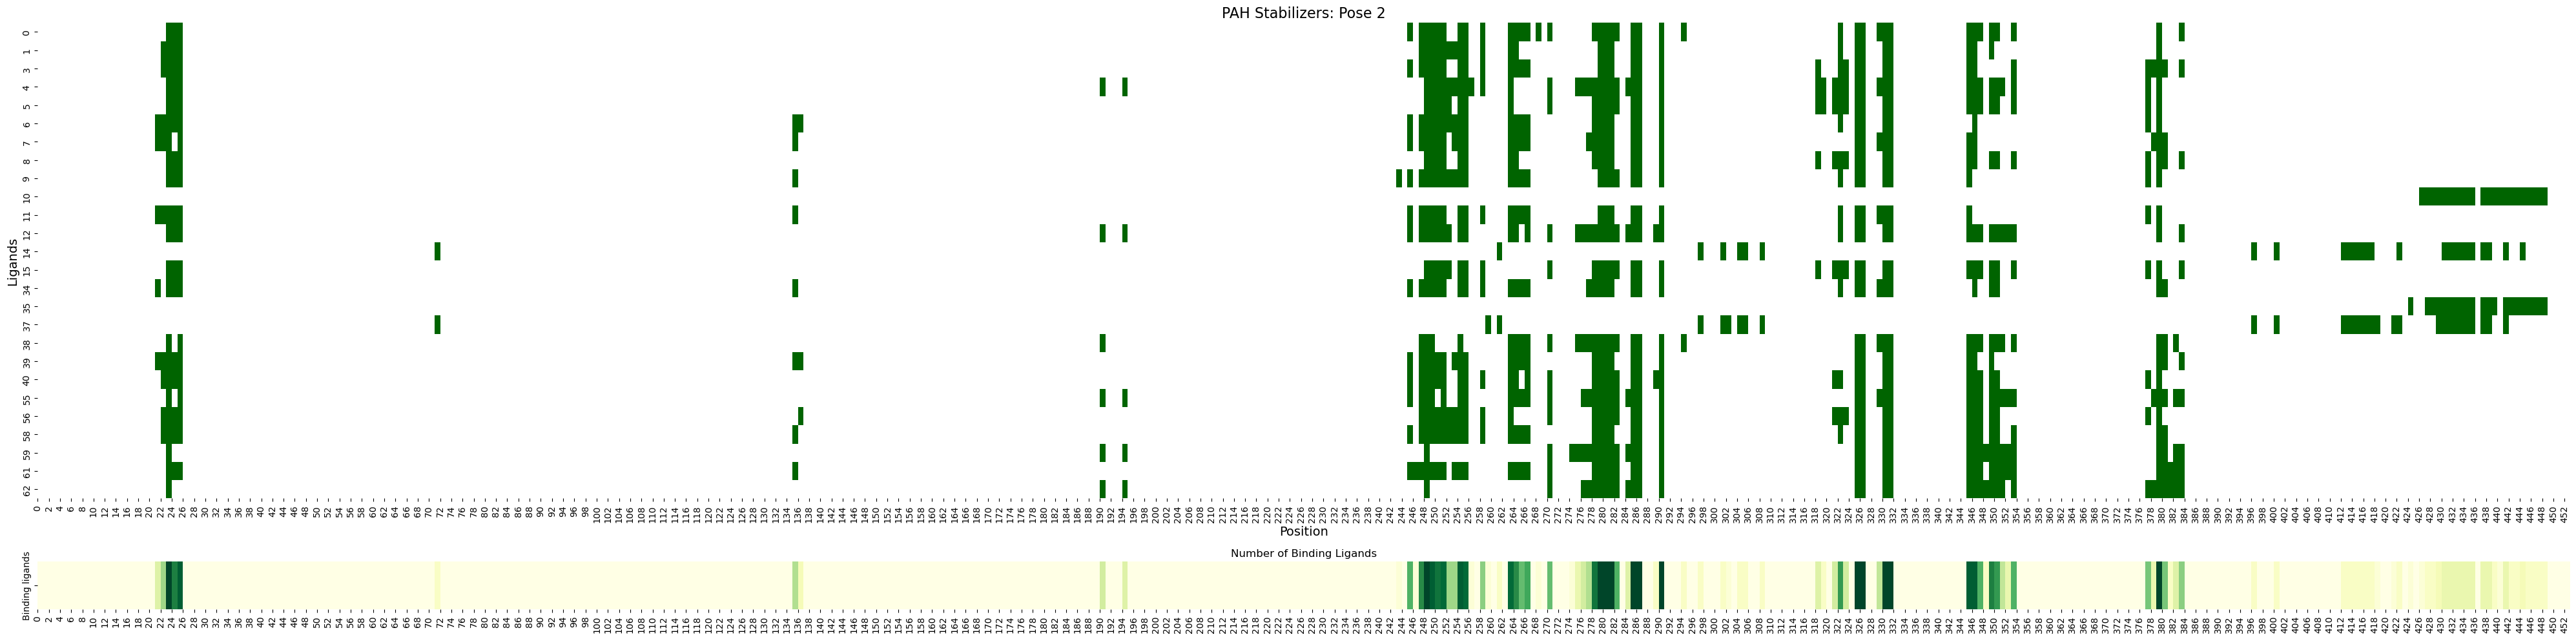

In [8]:
#Make the heatmap

#For gradient color and color selection
#https://www.practicalpythonfordatascience.com/ap_seaborn_palette
#Rewmember to change Name, Directory, and Pose number for each pose.

# Compute sum of 1s per column
#(df_PAH_ligands == 1): creates a data frame, a boolean (True/False) Data set. This means through my d_PAH_ligands, the code will analyse if 
                        #the given possition are 1 and then return true or false. 
#.sum(axis=0): sum dowm the columns (columns= 0) only sum the 0 thanks to boolean def. If 1 then it will be summed. 
#pd.DataFrame([heatmap_sum], index=["Binding ligands"]): creates a data frame that has the data from the sum and a row called 'Binding ligands'


heatmap_sum = (df_PAH_ligands == 1).sum(axis=0)
df_heatmap_sum = pd.DataFrame([heatmap_sum], index=["Binding ligands"])



fig, ax = plt.subplots(2, 1, figsize=(40, 10), gridspec_kw={'height_ratios': [1, 0.1]})

xticks = list(range(0, 453, 2))


# Plot main heatmap (binary matrix)
sns.heatmap(df_PAH_ligands, cmap=["white", "darkgreen"], cbar=False, ax=ax[0], 
            linewidths=0.001, linecolor='gray')

# Title and labels
ax[0].set_title('PAH Stabilizers: Pose 2', fontsize=16)
ax[0].set_xlabel('Position', fontsize=14)
ax[0].set_ylabel('Ligands', fontsize=14)
ax[0].tick_params(axis='x', rotation=90)
ax[0].set_xticks(xticks),
ax[0].set_xticklabels(xticks)


# Plot summary heatmap (only one row)
sns.heatmap(df_heatmap_sum, ax=ax[1], cmap="YlGn", cbar=False, 
            annot= False, fmt="")
ax[1].set_title("Number of Binding Ligands", fontsize=12)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)

# Show the figure
plt.tight_layout()
#plt.savefig('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/no_stabilizers/weak_binding/stabilizers_pose_2')
plt.show()
